In [58]:
# Bibliotecas utilizadas

import numpy as np
import matplotlib.pyplot as plt

# Constantes utilizadas

pi = np.pi

# FFT raiz 2 com decimação no tempo #

Seja $x(n)$ uma sequência com comprimenro $N$, onde $N$ é potência de 2 (com $N>1$), pode-se formar as sequências $x_e(n)=x(2n)$ e $x_o(n)=x(2n+1)$. Com isso, a DFT de $x(n)$ é dada por:

$$X(K) = X_e(k) + {W_N}^k X_o(k)\,,$$

onde $X_e(k)$ é a DFT de $x_e(n)$ e $X_o(k)$ é a DFT de $x_o(n)$. Como $N$ é potência de 2, $x_e(n)$ e $x_o(n)$ tem ambas comprimento $N/2$, que também é potência de 2. Dessa forma a mesma divisão pode ser realizadas para elas e suas DFTs também podem ser expressas da forma acima, até que sejam formadas sequências de comprimento $2$, cuja DFT é dada por:

$$X_m(0) = x_m(0) + x_m(1)$$
$$X_m(1) = x_m(0) - x_m(1)\,.$$

Com isso é possível formar um algoritmo otimizado para determinar a DFT de um sinal, denominado **FFT** (*Fast Fourier Transform*).

De forma semelhante, sendo $X(k)$ uma DFT de comprimento $N$, com $N$ potência de 2, é possível formar sequências $X_e(k)=X(2k)$ e $X_o(k)=X(2k+1)$. Dessa, a IDFT de $X(k)$ é dada por:

$$x(n)=X_e(k) + {W_N}^{-n}X_o(k)\,$$

ou seja, o algoritmo da FFT pode ser reaproveitado para determinar a IDFT de uma DFT. Nesse caso o algoritmo é denominado **IFFT** (*Inverse Fast Fourier Transform*).

In [59]:
def W(N):
    return np.exp(-2j*pi/N)

def FFT_recursiva(x, N):
    if N == 2:
        X0 = x[0] + x[1]
        X1 = x[0] - x[1]
        return np.array([X0, X1])

    xe = x[::2]
    xo = x[1::2]

    Xe = FFT_recursiva(xe, N//2)
    Xo = FFT_recursiva(xo, N//2)

    k = np.arange(0, N//2, 1)
    Xo_ponderado = W(N)**k * Xo

    Xk_primeira_metade = Xe + Xo_ponderado
    Xk_segunda_metade = Xe - Xo_ponderado

    return np.concatenate([Xk_primeira_metade, Xk_segunda_metade])

def FFT(x, N):
    if (not np.log2(N).is_integer()) or (N==1):
        raise ValueError('Esse algoritmo de FFT só funciona com N potência de 2, com N > 1')

    x_copy = x.copy()
    L = len(x_copy)

    if N < L:
        raise ValueError('N deve ser maior que o número de pontos de x(n)')
    if N > L:
        x_copy = np.append(x_copy, [0]*(N-L))

    return FFT_recursiva(x_copy, N)

def IFFT_recursiva(X,N):
    if N == 2:
        x0 = X[0] + X[1]
        x1 = X[0] - X[1]
        return np.array([x0,x1])
    
    Xe = X[::2]
    Xo = X[1::2]

    xe = IFFT_recursiva(Xe, N//2)
    xo = IFFT_recursiva(Xo, N//2)

    n = np.arange(0,N//2,1)
    xo_ponderado = W(N)**(-n) * xo

    xn_primeira_metade = xe + xo_ponderado
    xn_segunda_metade = xe - xo_ponderado

    return np.concatenate([xn_primeira_metade, xn_segunda_metade])

def IFFT(X):
    N = len(X)
    return IFFT_recursiva(X,N)/N

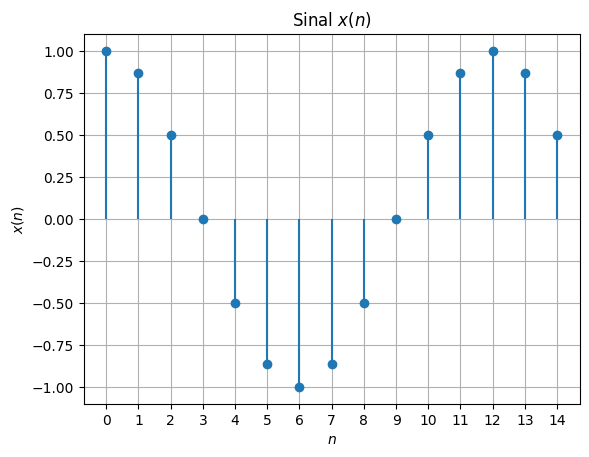

In [60]:
L = 15

A = 1

n_array = np.arange(0,L,1)
#x = A*np.ones(len(n_array))
x = A*np.cos(pi*n_array/6)

plt.stem(n_array, x, basefmt=' ')
plt.grid(True)
if L < 20:
    plt.xticks(n_array)
plt.title(r'Sinal $x(n)$')
plt.xlabel(r'$n$')
plt.ylabel(r'$x(n)$')
plt.show()

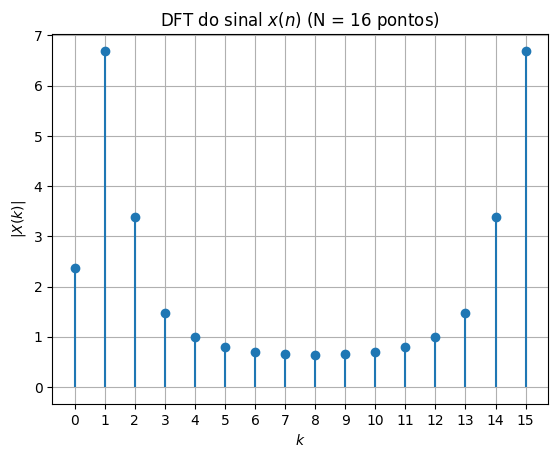

In [61]:
m = 4
N = 2**m

k_array = np.arange(0,N,1)
X = FFT(x, N)

plt.stem(k_array, np.abs(X), basefmt=' ')
plt.grid(True)
if N < 20:
    plt.xticks(k_array)
plt.title(r'DFT do sinal $x(n)$ (N = %d pontos)' %N)
plt.xlabel(r'$k$')
plt.ylabel(r'$|X(k)|$')
plt.show()

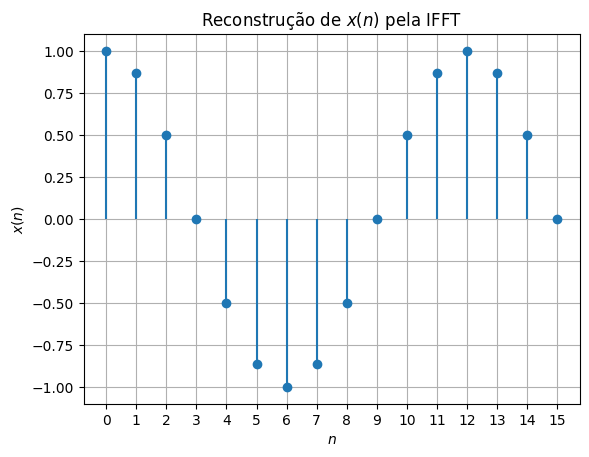

In [62]:
x_IDFT = np.real(IFFT(X))

plt.stem(k_array, x_IDFT, basefmt=' ')
plt.grid(True)
if N < 20:
    plt.xticks(k_array)
plt.title(r'Reconstrução de $x(n)$ pela IFFT')
plt.xlabel(r'$n$')
plt.ylabel(r'$x(n)$')
plt.show()